<a href="https://colab.research.google.com/github/mayank261193/Rebounce-Applied-AI-and-Analytics-Codes/blob/main/MP7_DistrictSegments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MP7_DistrictSegments
Segmenting India’s districts by health service reach · NFHS-5 (2019–21)

Upload the course CSV when prompted. Run Parts 1–8, then replace the prompts in the text cells with observations from your own outputs. Stunting and Aspirational District status are used only after fitting.

## 1 · Load and clean

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

path = Path('mp7_nfhs5_district_health.csv')
if not path.exists():
    from google.colab import files
    uploaded = files.upload()
    if path.name not in uploaded:
        raise FileNotFoundError(f'Upload {path.name} (the course CSV, not the PDF).')
raw = pd.read_csv(path)
raw.columns = raw.columns.str.strip().str.lower()
features = ['institutional_births_pct', 'full_vaccination_pct', 'anc_4visits_pct',
            'improved_sanitation_pct', 'clean_cooking_fuel_pct', 'health_insurance_pct']
district = next((x for x in ['district', 'district_name'] if x in raw), 'district')
state = next((x for x in ['state', 'state_name', 'state_ut'] if x in raw), 'state')
stunting, aspirational = 'stunted_children_pct', 'is_aspirational'
required = features + [district, state, stunting, aspirational]
missing = sorted(set(required) - set(raw.columns))
if missing:
    raise ValueError(f'Missing columns: {missing}. Available columns: {raw.columns.tolist()}')
placeholder = raw[district].astype('string').str.strip().str.casefold().eq('data not available').fillna(False)
df = raw.loc[~placeholder].copy()
df[features] = df[features].apply(pd.to_numeric, errors='coerce').replace(0, np.nan)
missing_features = df[features].isna().any(axis=1).sum()
df = df.dropna(subset=features).reset_index(drop=True)
print(f'Input: {len(raw)} | Placeholder: {placeholder.sum()} | Missing features: {missing_features} | Retained: {len(df)}')
display(df[features].describe().T.round(2))

Input: 707 | Placeholder: 1 | Missing features: 13 | Retained: 693


,count,mean,std,min,25%,50%,75%,max
institutional_births_pct,693.0,88.54,12.00,21.4,83.7,92.1,97.3,100.0
full_vaccination_pct,693.0,77.71,12.10,38.3,69.7,78.0,87.2,100.0
anc_4visits_pct,693.0,60.25,20.31,4.4,44.7,62.2,75.9,98.7
improved_sanitation_pct,693.0,71.78,14.26,29.2,62.0,73.5,83.2,99.9
clean_cooking_fuel_pct,693.0,53.83,24.09,8.6,33.8,49.5,75.0,99.8
health_insurance_pct,693.0,40.20,23.13,1.2,20.2,35.7,60.0,97.8


## 2 · Explore the six features

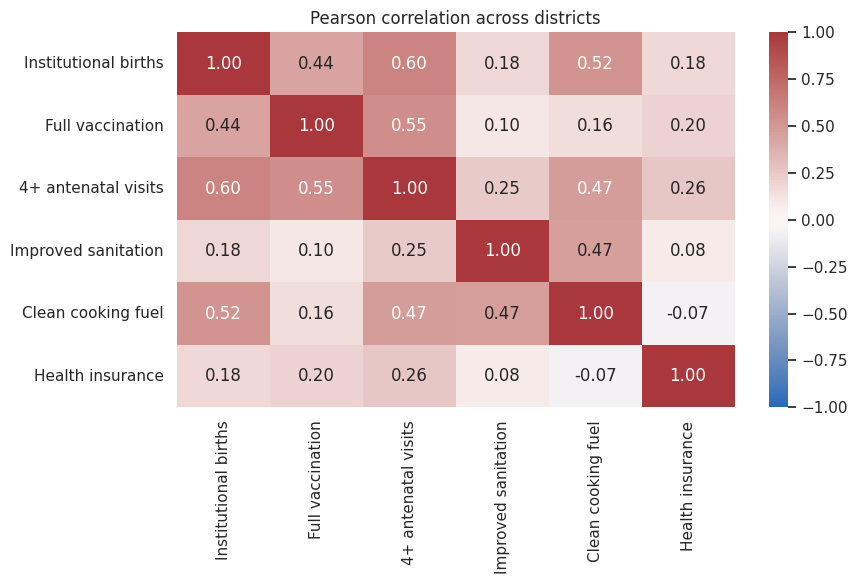

Strongest absolute correlation: Institutional births and 4+ antenatal visits (r=0.603)


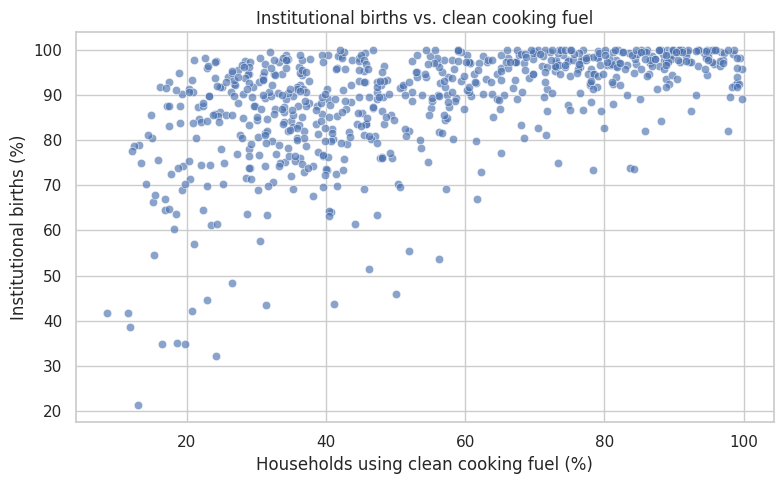

In [9]:
sns.set_theme(style='whitegrid')
x, y = 'clean_cooking_fuel_pct', 'institutional_births_pct'
labels = dict(zip(features, ['Institutional births', 'Full vaccination', '4+ antenatal visits',
                             'Improved sanitation', 'Clean cooking fuel', 'Health insurance']))
corr = df[features].rename(columns=labels).corr()
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt='.2f', vmin=-1, vmax=1, center=0, cmap='vlag', ax=ax)
ax.set_title('Pearson correlation across districts')
plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pair = pairs.abs().idxmax()
print(f'Strongest absolute correlation: {pair[0]} and {pair[1]} (r={pairs.loc[pair]:.3f})')

def scatter(hue=None):
    fig, ax = plt.subplots(figsize=(8, 5))
    kwargs = {'hue': hue, 'palette': 'tab10'} if hue else {}
    sns.scatterplot(data=df, x=x, y=y, alpha=.65, ax=ax, **kwargs)
    ax.set(xlabel='Households using clean cooking fuel (%)', ylabel='Institutional births (%)',
           title='Institutional births vs. clean cooking fuel')
    plt.tight_layout(); plt.show()
scatter()

**Interpretation to complete:** Report the strongest pair and its correlation. Does the scatter show distinct groups, overlapping clouds, or mostly a gradient? Remember it shows only two of the six inputs.

## 3 · Scale the features
K-Means uses squared Euclidean distances. Without scaling, a percentage with more district-to-district variation can contribute more to those distances, even though every input is measured in percentage points.

StandardScaler puts the six features on a common scale. Use the raw standard deviations below to compare how much insurance and institutional births vary before scaling.

In [10]:
X_scaled = StandardScaler().fit_transform(df[features])
scaled = pd.DataFrame(X_scaled, columns=features, index=df.index)
display(pd.DataFrame({'raw_sd_pp': df[features].std(ddof=0),
                      'scaled_sd': scaled.std(ddof=0)}).round(2))

,raw_sd_pp,scaled_sd
institutional_births_pct,11.99,1.0
full_vaccination_pct,12.09,1.0
anc_4visits_pct,20.30,1.0
improved_sanitation_pct,14.25,1.0
clean_cooking_fuel_pct,24.07,1.0
health_insurance_pct,23.11,1.0


## 4 · Choose k

,inertia,silhouette,inertia_drop_pct
1,4158.000,NaN,NaN
2,2915.408,0.272,29.884
3,2421.149,0.237,16.953
4,2171.445,0.247,10.313
5,1963.568,0.206,9.573
6,1768.302,0.221,9.944
7,1617.330,0.211,8.538
8,1519.843,0.201,6.028
9,1432.922,NaN,5.719
10,1372.721,NaN,4.201


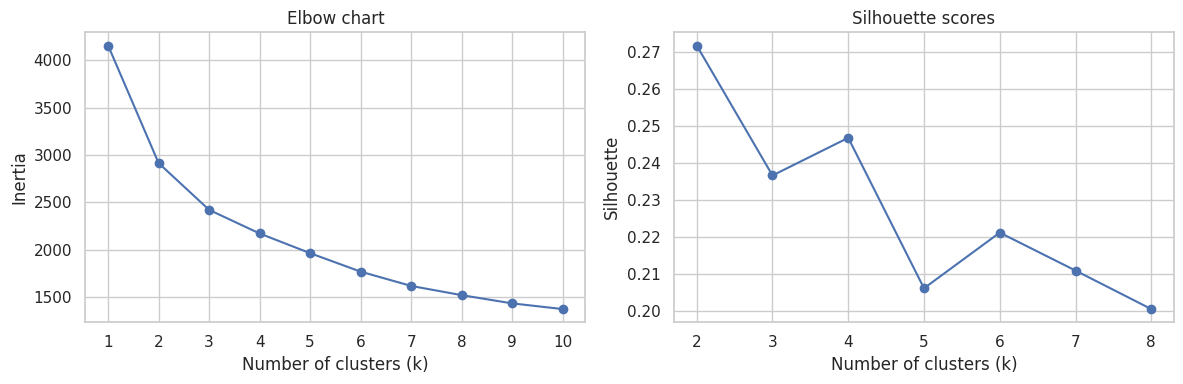

Starting choice: k=4


In [11]:
models = {k: KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
          for k in range(1, 11)}
scores = pd.DataFrame({'inertia': {k: model.inertia_ for k, model in models.items()},
                       'silhouette': {k: silhouette_score(X_scaled, models[k].labels_)
                                      for k in range(2, 9)}}).sort_index()
scores['inertia_drop_pct'] = -100 * scores.inertia.pct_change()
display(scores.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ['inertia', 'silhouette'], ['Elbow chart', 'Silhouette scores']):
    series = scores[metric].dropna()
    ax.plot(series.index, series, 'o-')
    ax.set(xlabel='Number of clusters (k)', ylabel=metric.title(), title=title, xticks=series.index)
plt.tight_layout(); plt.show()
# Starting choice among permitted values. Change if the elbow and profiles justify it.
chosen_k = int(scores.loc[3:5, 'silhouette'].idxmax())
print(f'Starting choice: k={chosen_k}')

**Justification to complete:** Where do inertia gains diminish? Compare silhouette scores for k = 3, 4, and 5 and explain whether the extra cluster gives a useful service profile.

## 5 · Fit and label

In [12]:
model = KMeans(n_clusters=chosen_k, n_init=10, random_state=42).fit(X_scaled)
df['cluster'] = model.labels_
display(df.cluster.value_counts().sort_index().rename('districts').to_frame())

,districts
cluster,
0,26
1,264
2,179
3,224


## 6 · Profile and name the clusters
For this notebook, *weakest* and *strongest* mean lowest and highest average standardized centroid across the six service indicators. This is an equal-weight summary, not an official performance ranking.

,institutional_births_pct,full_vaccination_pct,anc_4visits_pct,improved_sanitation_pct,clean_cooking_fuel_pct,health_insurance_pct,stunted_children_pct,name,mean_scaled_reach,stunting_n
cluster,,,,,,,,,,
0,48.74,59.55,36.50,82.95,27.31,36.09,36.93,0 · Improved sanitation leads; institutional b...,-1.08,26
1,96.14,81.87,73.65,81.10,78.19,38.66,29.22,1 · Clean cooking fuel leads; health insurance...,0.54,264
2,90.74,84.73,67.47,66.97,36.51,60.84,33.70,2 · Health insurance leads; clean cooking fuel...,0.16,179
3,82.44,69.29,41.44,63.35,42.05,26.02,38.54,3 · Broad gaps; lowest in 4+ antenatal visits,-0.64,224


Weakest: 0 · Improved sanitation leads; institutional births lags | Strongest: 1 · Clean cooking fuel leads; health insurance lags
Highest mean reported stunting: 3 · Broad gaps; lowest in 4+ antenatal visits (38.5%)


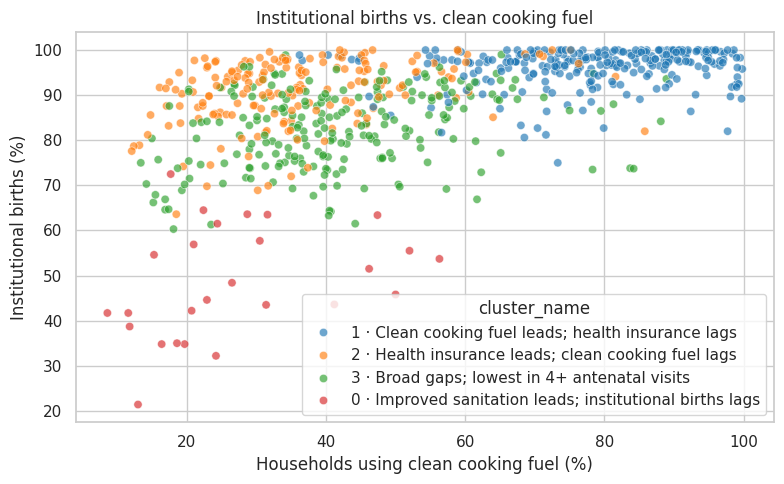

In [13]:
df[stunting] = pd.to_numeric(df[stunting], errors='coerce').replace(0, np.nan)
profiles = df.groupby('cluster')[features + [stunting]].mean()
centers = pd.DataFrame(model.cluster_centers_, columns=features).join(df.cluster.value_counts().rename('districts'))
reach = centers[features].mean(axis=1)
weakest, strongest = int(reach.idxmin()), int(reach.idxmax())
def profile_name(row):
    high, low = row.idxmax(), row.idxmin()
    if row.max() <= 0:
        return f'Broad gaps; lowest in {labels[low].lower()}'
    if row.min() >= 0:
        return f'Broad reach; highest in {labels[high].lower()}'
    return f'{labels[high]} leads; {labels[low].lower()} lags'
names = {k: f'{k} · {profile_name(row)}' for k, row in centers[features].iterrows()}
df['cluster_name'] = df.cluster.map(names)
display(profiles.assign(name=pd.Series(names), mean_scaled_reach=reach,
                        stunting_n=df.groupby('cluster')[stunting].count()).round(2))
print(f'Weakest: {names[weakest]} | Strongest: {names[strongest]}')
if profiles[stunting].notna().any():
    for k in profiles.index[profiles[stunting].eq(profiles[stunting].max())]:
        print(f'Highest mean reported stunting: {names[k]} ({profiles.loc[k, stunting]:.1f}%)')
scatter('cluster_name')

## 7 · The policy lens

In [14]:
flag = df[aspirational].astype('string').str.strip().str.casefold()
flag = flag.map({'1': 'Yes', '1.0': 'Yes', 'yes': 'Yes', 'true': 'Yes',
                 '0': 'No', '0.0': 'No', 'no': 'No', 'false': 'No'}).fillna('Unknown')
cross = pd.crosstab(df.cluster, flag).reindex(columns=['Yes', 'No', 'Unknown'], fill_value=0)
display(cross.assign(share_of_known_pct=(100 * cross.Yes / (cross.Yes + cross.No)).round(1)))
display(df.loc[df.cluster.eq(weakest), state].value_counts().head(5).rename('districts').to_frame())
# Find the closest pair in standardized feature space from different states but the same cluster.
from sklearn.metrics import pairwise_distances
states = df[state].fillna('').astype(str).str.strip().str.casefold().to_numpy()
clusters = df.cluster.to_numpy()
valid_pair = ((states[:, None] != states[None, :]) & (states[:, None] != '') &
              (states[None, :] != '') & (clusters[:, None] == clusters[None, :]))
if valid_pair.any():
    distances = np.where(valid_pair, pairwise_distances(X_scaled), np.inf)
    i, j = np.unravel_index(distances.argmin(), distances.shape)
    display(df.loc[[i, j], [district, state, 'cluster_name'] + features])
else:
    print('No eligible cross-state pair found.')

# Separation: share of each feature’s total variance explained by cluster membership.
total_ss = ((scaled - scaled.mean()) ** 2).sum()
between_ss = centers[features].sub(scaled.mean(), axis=1).pow(2).mul(centers.districts, axis=0).sum()
separation = (100 * between_ss / total_ss.replace(0, np.nan)).sort_values(ascending=False)
display(separation.rename(index=labels).rename('variance_between_clusters_pct').round(1).to_frame())

is_aspirational,Yes,No,Unknown,share_of_known_pct
cluster,,,,
0,5,21,0,19.2
1,15,249,0,5.7
2,37,142,0,20.7
3,55,169,0,24.6


,districts
state,
Nagaland,9
Meghalaya,7
Manipur,4
Arunachal Pradesh,2
Chhattisgarh,1


,district,state,cluster_name,institutional_births_pct,full_vaccination_pct,anc_4visits_pct,improved_sanitation_pct,clean_cooking_fuel_pct,health_insurance_pct
356,Nanded,Maharashtra,3 · Broad gaps; lowest in 4+ antenatal visits,94.8,75.7,53.5,68.0,64.5,15.7
633,Mahoba,Uttar Pradesh,3 · Broad gaps; lowest in 4+ antenatal visits,93.3,76.2,52.5,66.7,65.1,18.2


,variance_between_clusters_pct
Institutional births,65.9
Clean cooking fuel,64.7
4+ antenatal visits,52.8
Full vaccination,37.4
Health insurance,33.1
Improved sanitation,32.9


**Policy notes to complete:** Report the Aspirational counts, noting any unknown flags. List the five states (or all if fewer than five) with the most districts in the weakest cluster. For the cross-state pair, cite one or two similar percentages. Write one recommendation per cluster tied to a specific gap in the profile table; keep in mind that the widest gap is not always the easiest to address.

## 8 · Written answers
1. **Choice of k:** I chose **k = 4** (693 districts after dropping 1 placeholder row and 13 with missing features). Inertia falls 29.9% from k=1 to 2 and 17.0% from 2 to 3, then 10.3% from 3 to 4. After that each extra cluster only cuts it by about 6–10% (9.6% at k=5), so the elbow is gradual and gains diminish around k=4. Among the permitted values, silhouette is highest at k=4 (0.247) versus 0.237 at k=3 and 0.206 at k=5. The fourth cluster is also useful: it separates a small group with very low institutional births (cluster 0, 26 districts) from the large low-ANC group. Silhouettes are all below 0.3, so the clusters are a useful grouping of a continuum rather than sharply separated types.
2. **Weakest and strongest clusters:** The weakest is **cluster 0** (26 districts, mean scaled reach −1.08), with 48.7% institutional births and 36.5% ANC4+ visits, against 96.1% and 73.6% in the strongest cluster. The strongest is **cluster 1** (264 districts, mean scaled reach +0.54), with 96.1% institutional births and 78.2% clean cooking fuel, against 27.3% clean cooking fuel in cluster 0. Cluster 0 is not weak everywhere: its sanitation (83.0%) is the highest of any cluster.
3. **Aspirational Districts:** No, they are not all in the weakest cluster. Of the 112 retained flagged districts (581 not flagged, 0 unknown flags), only 5 are in cluster 0 (the weakest). Another 15 are in cluster 1, 37 in cluster 2 and 55 in cluster 3, so 82% sit in clusters 2 and 3. By share of each cluster, 24.6% of cluster 3 and 20.7% of cluster 2 are Aspirational, versus 19.2% of cluster 0 and 5.7% of cluster 1. Aspirational status is based on a broader basket than these six service indicators, and the weakest cluster is mostly Northeastern districts (Nagaland 9, Meghalaya 7, Manipur 4, Arunachal Pradesh 2, Assam 1). So the programme list and this clustering identify different kinds of need.
4. **Most separating feature:** **Institutional births** explains the most variance between clusters (65.9%), closely followed by clean cooking fuel (64.7%). Improved sanitation separates the least (32.9%).
5. **Limitation:** District averages can hide large differences within a district, so clusters should guide planning rather than determine resource allocation on their own.

## Final insight
Districts split into four service-reach profiles, and institutional births (65.9% of between-cluster variance) and clean cooking fuel (64.7%) separate them most. The weakest cluster is small (26 districts) and mostly in the Northeast, with 48.7% institutional births versus 96.1% in the strongest cluster, while the largest group of lagging districts is cluster 3 (224 districts), which is low on ANC4+ visits (41.4%) and health insurance (26.0%) and has the highest mean stunting (38.5%). Only 5 of the 112 Aspirational Districts fall in the weakest cluster, and 82% fall in clusters 2 and 3, so the programme list does not match service reach alone. On the data side, 14 of 707 rows were dropped, and the silhouette scores (about 0.25) show the groups overlap, so they are best read as a gradient with four useful bands. A targeted response would be to prioritise delivery capacity and facility access in cluster 0, ANC outreach in cluster 3, and clean cooking fuel and sanitation in cluster 2. The widest gap is not always the cheapest to close, so insurance enrolment (cluster 3) and ANC follow-up may be quicker wins than clean cooking fuel.
